# Week 6

,continent,countries,mean_life_expectancy,mean_deviation_pct
0,Africa,52,54.81,-18.21
2,Asia,33,70.73,5.55
1,Americas,25,73.61,9.85
3,Europe,30,77.65,15.88
4,Oceania,2,80.72,20.46


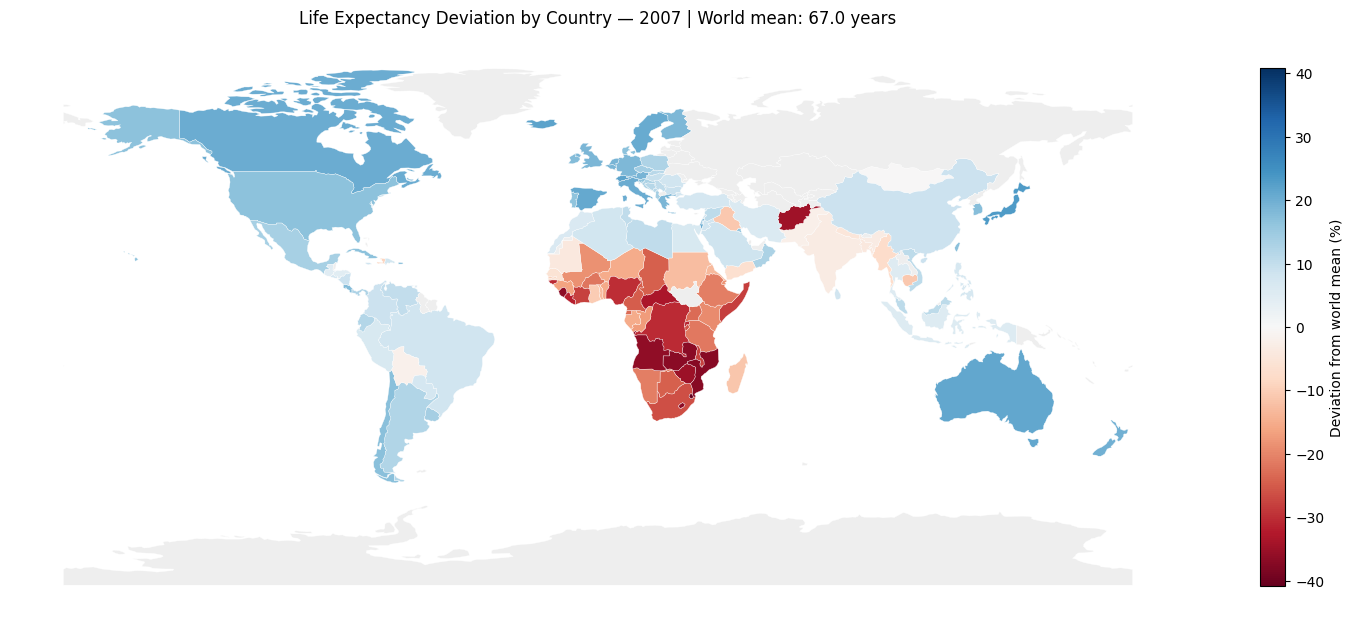

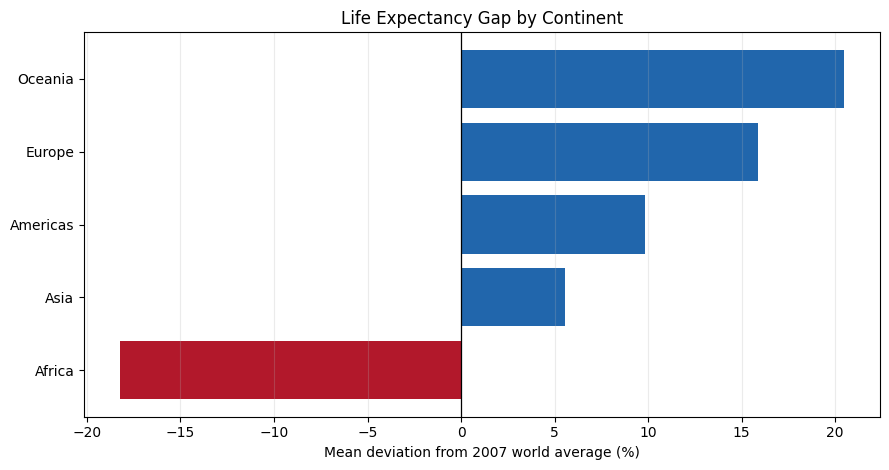

In [1]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import geopandas as gpd
import base64
import io
from IPython.display import display

gapminder = px.data.gapminder()
data = gapminder.loc[gapminder["year"] == 2007].copy()

world_mean = data["lifeExp"].mean()
data["deviation_pct"] = ((data["lifeExp"] - world_mean) / world_mean) * 100

continent = (
    data.groupby("continent", as_index=False)
    .agg(
        countries=("country", "count"),
        mean_life_expectancy=("lifeExp", "mean"),
        mean_deviation_pct=("deviation_pct", "mean")
    )
    .sort_values("mean_deviation_pct")
    .round(2)
)

lowest = continent.iloc[0]
display(continent)

# Country-level comparison uses px.choropleth; RdBu is diverging because values fall on both sides of zero.
fig1 = px.choropleth(
    data,
    locations="iso_alpha",
    locationmode="ISO-3",
    color="deviation_pct",
    color_continuous_scale="RdBu",
    color_continuous_midpoint=0,
    hover_name="country",
    hover_data={"lifeExp":":.1f", "deviation_pct":":+.2f", "iso_alpha":False},
    labels={
        "lifeExp":"Life expectancy (years)",
        "deviation_pct":"Deviation from world mean (%)"
    },
    title=f"{lowest['continent']} Has the Largest Life-Expectancy Deficit ({lowest['mean_deviation_pct']:.1f}%)",
    height=580
)
fig1.update_geos(showframe=False)
fig1.update_layout(
    margin=dict(l=5, r=5, t=75, b=5),
    coloraxis_colorbar_title="Deviation (%)"
)
fig1.show()

world_geojson_b64 = """..."""
world_map = gpd.read_file(io.StringIO(base64.b64decode(world_geojson_b64).decode("utf-8")))
world_map = world_map.merge(data[["iso_alpha", "deviation_pct", "country", "lifeExp"]], left_on="iso_a3", right_on="iso_alpha", how="left")
limit = max(abs(world_map["deviation_pct"].min()), abs(world_map["deviation_pct"].max()))
fig, ax = plt.subplots(figsize=(15, 7.5))
world_map.plot(column="deviation_pct", cmap="RdBu", vmin=-limit, vmax=limit, legend=True,
               missing_kwds={"color": "#eeeeee", "label": "No data"},
               legend_kwds={"label": "Deviation from world mean (%)", "shrink": 0.72},
               linewidth=0.25, edgecolor="white", ax=ax)
ax.set_title(f"Life Expectancy Deviation by Country — 2007 | World mean: {world_mean:.1f} years", pad=14)
ax.axis("off")
fig.tight_layout()
plt.show()


fig2, ax = plt.subplots(figsize=(9, 4.8))
ordered = continent.sort_values("mean_deviation_pct")
bar_colors = ["#b2182b" if value < 0 else "#2166ac" for value in ordered["mean_deviation_pct"]]
ax.barh(ordered["continent"], ordered["mean_deviation_pct"], color=bar_colors)
ax.axvline(0, color="black", linewidth=0.9)
ax.set_xlabel("Mean deviation from 2007 world average (%)")
ax.set_title("Life Expectancy Gap by Continent")
ax.grid(axis="x", alpha=0.25)
fig2.tight_layout()
plt.show()


,district,population,deviation_pct
0,Pankow,415221,31.66
1,Mitte,384172,21.82
2,Tempelhof - Schöneberg,351622,11.50
3,Charlottenburg-Wilm.,343276,8.85
4,Neukölln,335335,6.33
5,Steglitz - Zehlendorf,308706,-2.11
6,Friedrichshain-Kreuzberg,295864,-6.18
7,Lichtenberg,295386,-6.34
8,Treptow - Köpenick,272843,-13.48
9,Marzahn - Hellersdorf,271038,-14.06


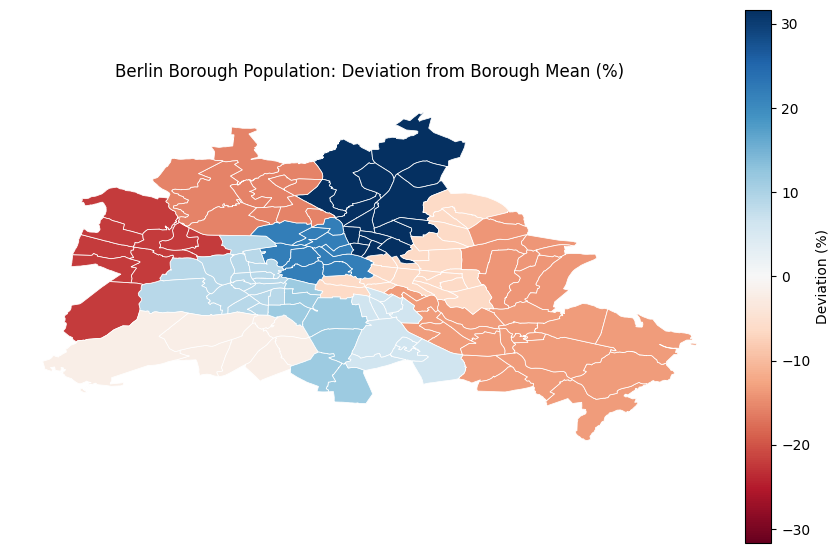

In [2]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import json
import base64
from IPython.display import display

berlin_population = pd.DataFrame({
    "district": [
        "Charlottenburg-Wilm.", "Friedrichshain-Kreuzberg", "Pankow",
        "Spandau", "Steglitz - Zehlendorf", "Tempelhof - Schöneberg",
        "Neukölln", "Treptow - Köpenick", "Marzahn - Hellersdorf",
        "Lichtenberg", "Reinickendorf", "Mitte"
    ],
    "population": [
        343276, 295864, 415221, 245197, 308706, 351622,
        335335, 272843, 271038, 295386, 265755, 384172
    ]
})

geojson_text = base64.b64decode(
    "..."
).decode("utf-8")
berlin_geojson = json.loads(geojson_text)
berlin_geojson["features"] = [
    feature for feature in berlin_geojson["features"]
    if feature["properties"].get("neighbourhood_group")
]

borough_mean = berlin_population["population"].mean()
berlin_population["deviation_pct"] = (
    (berlin_population["population"] - borough_mean) / borough_mean
) * 100

display(
    berlin_population.sort_values("deviation_pct", ascending=False)
    .round({"deviation_pct": 2})
    .reset_index(drop=True)
)

# GeoJSON boundaries are supplied directly, so px.choropleth avoids unnecessary basemap tiles.
# RdBu is diverging because borough populations are compared with the average borough population.
fig3 = px.choropleth(
    berlin_population,
    geojson=berlin_geojson,
    locations="district",
    featureidkey="properties.neighbourhood_group",
    color="deviation_pct",
    color_continuous_scale="RdBu",
    color_continuous_midpoint=0,
    hover_name="district",
    hover_data={"population":":,", "deviation_pct":":+.2f"},
    labels={
        "population":"Population",
        "deviation_pct":"Deviation from borough mean (%)"
    },
    title="Pankow Has the Highest Population Relative to the Borough Average",
    height=650
)
fig3.update_geos(fitbounds="locations", visible=False)
fig3.update_layout(
    margin=dict(l=0, r=0, t=65, b=0),
    coloraxis_colorbar_title="Deviation (%)"
)
fig3.show()

population_lookup = dict(zip(
    berlin_population["district"], berlin_population["deviation_pct"]
))
fig, ax = plt.subplots(figsize=(8.5, 8.5))
cmap = plt.get_cmap("RdBu")
norm = plt.Normalize(
    vmin=-max(abs(berlin_population["deviation_pct"])),
    vmax=max(abs(berlin_population["deviation_pct"]))
)
for feature in berlin_geojson["features"]:
    district = feature["properties"].get("neighbourhood_group")
    value = population_lookup.get(district)
    if value is None:
        continue
    geometry = feature["geometry"]
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    for polygon in polygons:
        ring = polygon[0]
        ax.fill(
            [point[0] for point in ring],
            [point[1] for point in ring],
            facecolor=cmap(norm(value)),
            edgecolor="white",
            linewidth=0.55
        )

ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Berlin Borough Population: Deviation from Borough Mean (%)", pad=14)
scalar = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
scalar.set_array([])
colorbar = fig.colorbar(scalar, ax=ax, fraction=0.035, pad=0.02)
colorbar.set_label("Deviation (%)")
fig.tight_layout()
plt.show()
